In [1]:
# from huggingface_hub import HfApi, HfFolder, upload_file

# # Step 1: Login using your Hugging Face token
# # You can get your token from: https://huggingface.co/settings/tokens
# HfFolder.save_token("YOUR_HF_TOKEN")  # 🔐 Paste your token here

# # Step 2: Define paths and repo
# local_file_path = "/x1/ljiao/Bhanu/VIBE/Project/output/processed_dance.zip"
# repo_id = "ThotaBhanu/3Dhumanmesh"  # Your dataset repo
# path_in_repo = "processed_dance.zip"

# # Step 3: Upload the file
# api = HfApi()
# upload_file(
#     path_or_fileobj=local_file_path,
#     path_in_repo=path_in_repo,
#     repo_id=repo_id,
#     repo_type="dataset"
# )

# print("✅ Upload successful!")


In [17]:
!which ffmpeg

/x4/ljiao/.conda/envs/vibe-env-conda/bin/ffmpeg


In [3]:
# import os
# import sys
# os.environ['PYOPENGL_PLATFORM'] = 'egl'


# conda_prefix = sys.prefix  # Gets your current conda env path
# os.environ['PATH'] = f"{conda_prefix}/bin:" + os.environ['PATH']

# import cv2
# import time
# import torch
# import joblib
# import shutil
# import colorsys
# import argparse
# import numpy as np
# from tqdm import tqdm
# from multi_person_tracker import MPT
# from torch.utils.data import DataLoader

# from lib.models.vibe import VIBE_Demo
# from lib.utils.renderer import Renderer
# from lib.dataset.inference import Inference
# from lib.utils.smooth_pose import smooth_pose
# from lib.data_utils.kp_utils import convert_kps
# from lib.utils.pose_tracker import run_posetracker
# import json
# from collections import defaultdict

# from lib.utils.demo_utils import (
#     download_youtube_clip,
#     smplify_runner,
#     convert_crop_coords_to_orig_img,
#     convert_crop_cam_to_orig_img,
#     prepare_rendering_results,
#     video_to_images,
#     images_to_video,
#     download_ckpt,
# )

# MIN_NUM_FRAMES = 15

In [4]:
import cv2
cap = cv2.VideoCapture('output_6.mkv')
ret, frame = cap.read()
cv2.imwrite('test_image.jpg', frame)
cap.release()

Running "ffmpeg -i output_6.mkv -f image2 -v error output/output_6_mkv_frames/output_6_mkv_%06d.png"
Images saved to "output/output_6_mkv_frames"


  0%|          | 0/76 [00:00<?, ?it/s]

Running Multi-Person-Tracker


100%|██████████| 76/76 [00:43<00:00,  2.04it/s]


Finished. Detection + Tracking FPS 20.87


/x4/ljiao/.conda/envs/vibe-env-conda/lib/python3.8/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/x4/ljiao/.conda/envs/vibe-env-conda/lib/python3.8/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


=> loaded pretrained model from 'data/vibe_data/spin_model_checkpoint.pth.tar'
Original beta[1]: 0.2354
Modified beta[1]: 2.2354 (offset: 2.0)


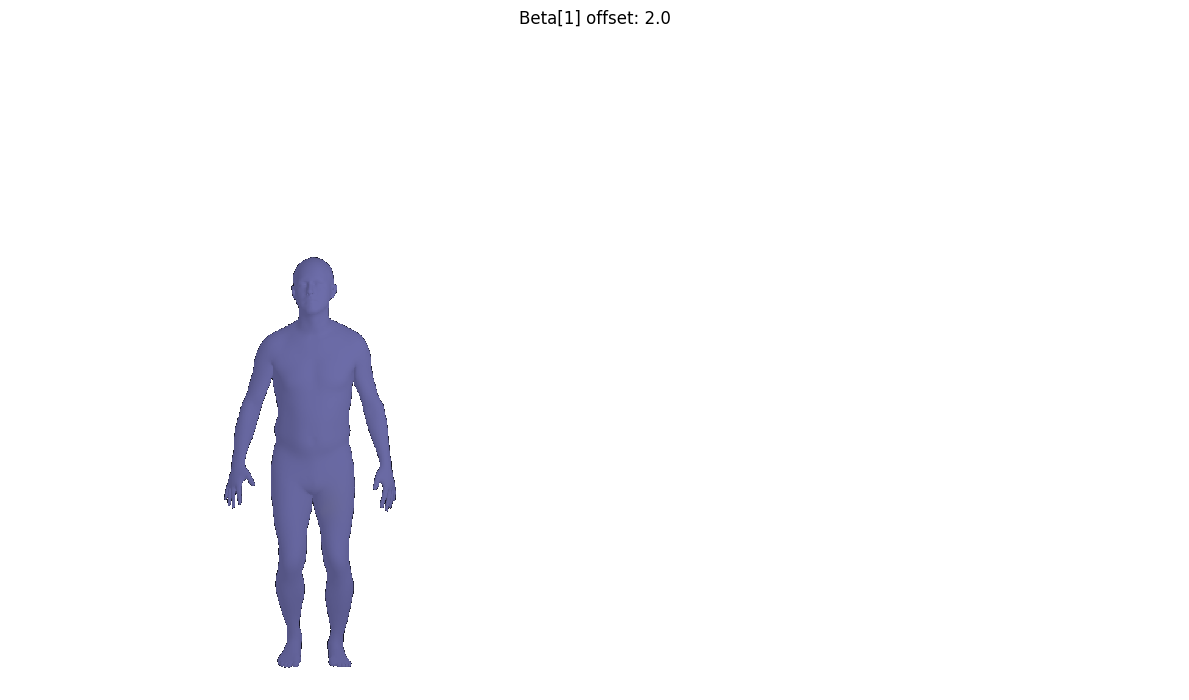

In [8]:
# import os
# import sys
# os.environ['PYOPENGL_PLATFORM'] = 'egl'

# os.environ['CUDA_VISIBLE_DEVICES'] = '1'  # Use GPU 1

# conda_prefix = sys.prefix  # Gets your current conda env path
# os.environ['PATH'] = f"{conda_prefix}/bin:" + os.environ['PATH']

# import cv2
# import time
# import torch
# import joblib
# import shutil
# import colorsys
# import argparse
# import numpy as np
# from tqdm import tqdm
# from multi_person_tracker import MPT
# from torch.utils.data import DataLoader

# from lib.models.vibe import VIBE_Demo
# from lib.utils.renderer import Renderer
# from lib.dataset.inference import Inference
# from lib.utils.smooth_pose import smooth_pose
# from lib.data_utils.kp_utils import convert_kps
# from lib.utils.pose_tracker import run_posetracker
# import json
# from collections import defaultdict

# import matplotlib.pyplot as plt

# from lib.utils.demo_utils import (
#     download_youtube_clip,
#     smplify_runner,
#     convert_crop_coords_to_orig_img,
#     convert_crop_cam_to_orig_img,
#     prepare_rendering_results,
#     video_to_images,
#     images_to_video,
#     download_ckpt,
# )

# MIN_NUM_FRAMES = 15

# def test_fatness(video_file, fatness_offset=2.0):
#     device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
    
#     # Get video frames
#     image_folder, num_frames, img_shape = video_to_images(video_file, return_info=True)
#     orig_height, orig_width = img_shape[:2]
    
#     # Run tracker (just to get bounding boxes)
#     mot = MPT(device=device, batch_size=12, display=False, detector_type='yolo', output_format='dict')
#     tracking_results = mot(image_folder)
    
#     # Get first person only
#     person_id = list(tracking_results.keys())[0]
#     bboxes = tracking_results[person_id]['bbox']
#     frames = tracking_results[person_id]['frames']
    
#     # Load VIBE model
#     model = VIBE_Demo(seqlen=15, n_layers=2, hidden_size=1024, add_linear=True, use_residual=True).to(device)
#     pretrained_file = download_ckpt(use_3dpw=False)
#     ckpt = torch.load(pretrained_file, map_location='cpu')
#     model.load_state_dict(ckpt['gen_state_dict'], strict=False)
#     model.eval()
    
#     # Prepare dataset
#     dataset = Inference(image_folder=image_folder, frames=frames, bboxes=bboxes, scale=1.1)
#     dataloader = DataLoader(dataset, batch_size=450, num_workers=16)
    
#     # Run inference
#     with torch.no_grad():
#         pred_cam, pred_verts, pred_betas = [], [], []
        
#         for batch in dataloader:
#             batch = batch.unsqueeze(0).to(device)
#             batch_size, seqlen = batch.shape[:2]
#             output = model(batch)[-1]
            
#             pred_cam.append(output['theta'][:, :, :3].reshape(batch_size * seqlen, -1))
#             pred_verts.append(output['verts'].reshape(batch_size * seqlen, -1, 3))
#             pred_betas.append(output['theta'][:, :, 75:].reshape(batch_size * seqlen, -1))
        
#         pred_cam = torch.cat(pred_cam, dim=0).cpu().numpy()
#         pred_verts = torch.cat(pred_verts, dim=0).cpu().numpy()
#         pred_betas = torch.cat(pred_betas, dim=0).cpu().numpy()
    
#     # ============ MODIFY BETA[1] HERE ============
#     print(f"Original beta[1]: {pred_betas[0, 1]:.4f}")
#     pred_betas[:, 1] += fatness_offset
#     print(f"Modified beta[1]: {pred_betas[0, 1]:.4f} (offset: {fatness_offset})")
#     # ============================================
    
#     # Get first frame to visualize
#     frame_idx = 0
#     frame_verts = pred_verts[frame_idx]
#     frame_cam = pred_cam[frame_idx]
#     frame_bbox = bboxes[frame_idx]
    
#     # Convert camera to original image space
#     orig_cam = convert_crop_cam_to_orig_img(
#         cam=frame_cam.reshape(1, -1),
#         bbox=frame_bbox.reshape(1, -1),
#         img_width=orig_width,
#         img_height=orig_height
#     )[0]
    
#     # Render ONLY first frame
#     renderer = Renderer(resolution=(orig_width, orig_height), orig_img=True, wireframe=False)
#     img = np.ones((orig_height, orig_width, 3), dtype=np.uint8) * 255  # White background
    
#     img = renderer.render(img, frame_verts, cam=orig_cam, color=(0.8, 0.3, 0.3))

#     # Convert BGR to RGB for matplotlib
#     img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
#     plt.figure(figsize=(12, 8))
#     plt.imshow(img_rgb)
#     plt.title(f'Beta[1] offset: {fatness_offset}')
#     plt.axis('off')
#     plt.tight_layout()
#     plt.show()
    
#     # # Save single image
#     # cv2.imwrite('test_fatness.png', img)
#     # print(f"✓ Saved test image to 'test_fatness.png'")
    
#     return img

# # Run test
# if __name__ == '__main__':
#     video_file = 'output_6.mkv'  # Change this
    
#     # Test different fatness levels
#     test_fatness(video_file, fatness_offset=2.0)  # Try: -2.0, 0, 2.0, 5.0

Found 906 frames at /x4/ljiao/Bhanu/VIBE/output/output_6_mkv_frames
Image size: 1920x1080


  0%|          | 0/76 [00:00<?, ?it/s]

Running Multi-Person-Tracker


100%|██████████| 76/76 [00:42<00:00,  2.07it/s]


Finished. Detection + Tracking FPS 21.23
Detected 1 person(s)
Processing 906 frames for person 11


/x4/ljiao/.conda/envs/vibe-env-conda/lib/python3.8/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/x4/ljiao/.conda/envs/vibe-env-conda/lib/python3.8/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


=> loaded pretrained model from 'data/vibe_data/spin_model_checkpoint.pth.tar'

Original beta[1]: 0.2354
Modified beta[1]: 50.2354 (offset: 50.0)


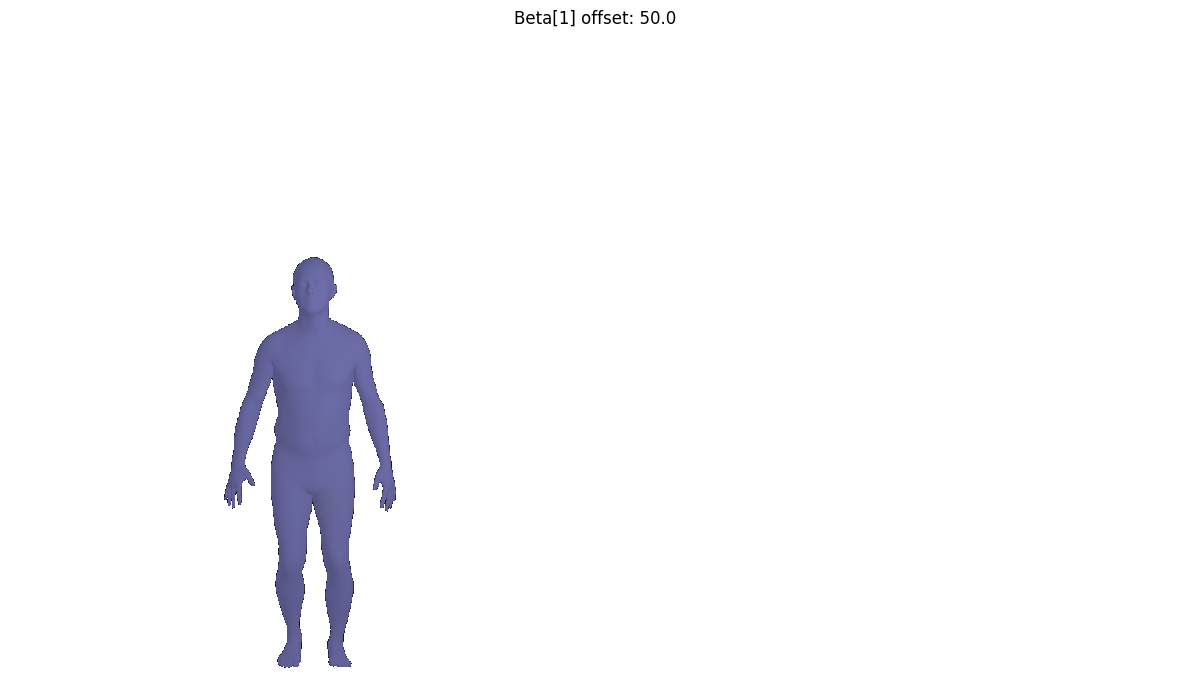

In [23]:
import os
import sys
os.environ['PYOPENGL_PLATFORM'] = 'egl'
os.environ['CUDA_VISIBLE_DEVICES'] = '1'  # Use GPU 1

conda_prefix = sys.prefix
os.environ['PATH'] = f"{conda_prefix}/bin:" + os.environ['PATH']

import cv2
import torch
import numpy as np
from tqdm import tqdm
from multi_person_tracker import MPT
from torch.utils.data import DataLoader

from lib.models.vibe import VIBE_Demo
from lib.utils.renderer import Renderer
from lib.dataset.inference import Inference

from lib.utils.demo_utils import (
    convert_crop_cam_to_orig_img,
    download_ckpt,
)

import matplotlib.pyplot as plt

MIN_NUM_FRAMES = 15

def test_fatness(image_folder, fatness_offset):
    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
    
    # ============ USE EXISTING FRAMES ============
    # Get image dimensions from first frame
    image_files = sorted([f for f in os.listdir(image_folder) if f.endswith('.png')])
    first_img_path = os.path.join(image_folder, image_files[0])
    sample_img = cv2.imread(first_img_path)
    orig_height, orig_width = sample_img.shape[:2]
    num_frames = len(image_files)
    
    print(f"Found {num_frames} frames at {image_folder}")
    print(f"Image size: {orig_width}x{orig_height}")
    # ============================================
    
    # Run tracker (just to get bounding boxes)
    mot = MPT(device=device, batch_size=12, display=False, detector_type='yolo', output_format='dict')
    tracking_results = mot(image_folder)
    
    # Get first person only
    person_id = list(tracking_results.keys())[0]
    bboxes = tracking_results[person_id]['bbox']
    frames = tracking_results[person_id]['frames']
    
    print(f"Detected {len(tracking_results)} person(s)")
    print(f"Processing {len(frames)} frames for person {person_id}")
    
    # Load VIBE model
    model = VIBE_Demo(seqlen=15, n_layers=2, hidden_size=1024, add_linear=True, use_residual=True).to(device)
    pretrained_file = download_ckpt(use_3dpw=False)
    ckpt = torch.load(pretrained_file, map_location='cpu')
    model.load_state_dict(ckpt['gen_state_dict'], strict=False)
    model.eval()
    
    # Prepare dataset
    dataset = Inference(image_folder=image_folder, frames=frames, bboxes=bboxes, scale=1.1)
    dataloader = DataLoader(dataset, batch_size=450, num_workers=16)
    
    # Run inference
    with torch.no_grad():
        pred_cam, pred_verts, pred_betas = [], [], []
        
        for batch in dataloader:
            batch = batch.unsqueeze(0).to(device)
            batch_size, seqlen = batch.shape[:2]
            output = model(batch)[-1]
            
            pred_cam.append(output['theta'][:, :, :3].reshape(batch_size * seqlen, -1))
            pred_verts.append(output['verts'].reshape(batch_size * seqlen, -1, 3))
            pred_betas.append(output['theta'][:, :, 75:].reshape(batch_size * seqlen, -1))
        
        pred_cam = torch.cat(pred_cam, dim=0).cpu().numpy()
        pred_verts = torch.cat(pred_verts, dim=0).cpu().numpy()
        pred_betas = torch.cat(pred_betas, dim=0).cpu().numpy()
    
    # ============ MODIFY BETA[1] HERE ============
    print(f"\nOriginal beta[1]: {pred_betas[0, 1]:.4f}")
    pred_betas[:, 1] += fatness_offset
    print(f"Modified beta[1]: {pred_betas[0, 1]:.4f} (offset: {fatness_offset})")
    # ============================================
    
    # Get first frame to visualize
    frame_idx = 0
    frame_verts = pred_verts[frame_idx]
    frame_cam = pred_cam[frame_idx]
    frame_bbox = bboxes[frame_idx]
    
    # Convert camera to original image space
    orig_cam = convert_crop_cam_to_orig_img(
        cam=frame_cam.reshape(1, -1),
        bbox=frame_bbox.reshape(1, -1),
        img_width=orig_width,
        img_height=orig_height
    )[0]
    
    # Render ONLY first frame
    renderer = Renderer(resolution=(orig_width, orig_height), orig_img=True, wireframe=False)
    img = np.ones((orig_height, orig_width, 3), dtype=np.uint8) * 255  # White background
    
    img = renderer.render(img, frame_verts, cam=orig_cam, color=(0.8, 0.3, 0.3))
    
    # ============ PLOT ============
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(12, 8))
    plt.imshow(img_rgb)
    plt.title(f'Beta[1] offset: {fatness_offset}')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    # ==============================
    
    return img

# Run test
if __name__ == '__main__':
    # USE EXISTING FRAME FOLDER
    image_folder = '/x4/ljiao/Bhanu/VIBE/output/output_6_mkv_frames'
    
    # Test different fatness levels
    test_fatness(image_folder, fatness_offset=50.0)  # Try: -2.0, 0, 2.0, 5.0

Found 906 frames at /x4/ljiao/Bhanu/VIBE/output/output_6_mkv_frames
Image size: 1920x1080



  0%|          | 0/76 [00:00<?, ?it/s]

Running Multi-Person-Tracker



100%|██████████| 76/76 [00:42<00:00,  2.06it/s]


Finished. Detection + Tracking FPS 21.28
Detected 1 person(s)
Processing 906 frames for person 14


/x4/ljiao/.conda/envs/vibe-env-conda/lib/python3.8/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/x4/ljiao/.conda/envs/vibe-env-conda/lib/python3.8/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


=> loaded pretrained model from 'data/vibe_data/spin_model_checkpoint.pth.tar'

Original beta[1]: 0.2354
Modified beta[1]: 10.2354 (offset: 10.0)


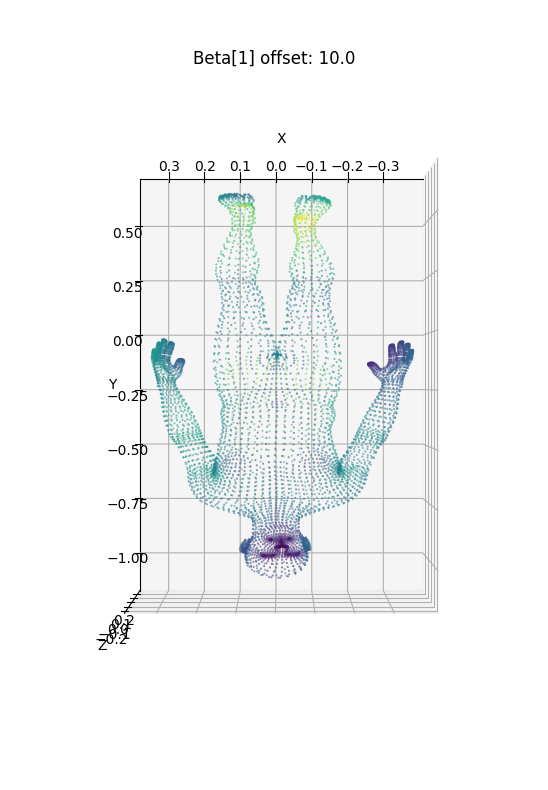

In [26]:
import os
import sys
os.environ['PYOPENGL_PLATFORM'] = 'egl'
os.environ['CUDA_VISIBLE_DEVICES'] = '1'

conda_prefix = sys.prefix
os.environ['PATH'] = f"{conda_prefix}/bin:" + os.environ['PATH']

import cv2
import torch
import numpy as np
from tqdm import tqdm
from multi_person_tracker import MPT
from torch.utils.data import DataLoader

from lib.models.vibe import VIBE_Demo
from lib.dataset.inference import Inference

from lib.utils.demo_utils import (
    convert_crop_cam_to_orig_img,
    download_ckpt,
)

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

MIN_NUM_FRAMES = 15

def test_fatness(image_folder, fatness_offset):
    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
    
    # ============ USE EXISTING FRAMES ============
    image_files = sorted([f for f in os.listdir(image_folder) if f.endswith('.png')])
    first_img_path = os.path.join(image_folder, image_files[0])
    sample_img = cv2.imread(first_img_path)
    orig_height, orig_width = sample_img.shape[:2]
    num_frames = len(image_files)
    
    print(f"Found {num_frames} frames at {image_folder}")
    print(f"Image size: {orig_width}x{orig_height}")
    # ============================================
    
    # Run tracker (just to get bounding boxes)
    mot = MPT(device=device, batch_size=12, display=False, detector_type='yolo', output_format='dict')
    tracking_results = mot(image_folder)
    
    # Get first person only
    person_id = list(tracking_results.keys())[0]
    bboxes = tracking_results[person_id]['bbox']
    frames = tracking_results[person_id]['frames']
    
    print(f"Detected {len(tracking_results)} person(s)")
    print(f"Processing {len(frames)} frames for person {person_id}")
    
    # Load VIBE model
    model = VIBE_Demo(seqlen=15, n_layers=2, hidden_size=1024, add_linear=True, use_residual=True).to(device)
    pretrained_file = download_ckpt(use_3dpw=False)
    ckpt = torch.load(pretrained_file, map_location='cpu')
    model.load_state_dict(ckpt['gen_state_dict'], strict=False)
    model.eval()
    
    # Prepare dataset
    dataset = Inference(image_folder=image_folder, frames=frames, bboxes=bboxes, scale=1.1)
    dataloader = DataLoader(dataset, batch_size=450, num_workers=16)
    
    # Run inference
    with torch.no_grad():
        pred_cam, pred_verts, pred_betas = [], [], []
        
        for batch in dataloader:
            batch = batch.unsqueeze(0).to(device)
            batch_size, seqlen = batch.shape[:2]
            output = model(batch)[-1]
            
            pred_cam.append(output['theta'][:, :, :3].reshape(batch_size * seqlen, -1))
            pred_verts.append(output['verts'].reshape(batch_size * seqlen, -1, 3))
            pred_betas.append(output['theta'][:, :, 75:].reshape(batch_size * seqlen, -1))
        
        pred_cam = torch.cat(pred_cam, dim=0).cpu().numpy()
        pred_verts = torch.cat(pred_verts, dim=0).cpu().numpy()
        pred_betas = torch.cat(pred_betas, dim=0).cpu().numpy()
    
    # ============ MODIFY BETA[1] HERE ============
    print(f"\nOriginal beta[1]: {pred_betas[0, 1]:.4f}")
    pred_betas[:, 1] += fatness_offset
    print(f"Modified beta[1]: {pred_betas[0, 1]:.4f} (offset: {fatness_offset})")
    # ============================================
    
    # Get first frame vertices
    frame_idx = 0
    vertices = pred_verts[frame_idx]  # Shape: (6890, 3)
    
    # ============ PLOT 3D MESH ============
    fig = plt.figure(figsize=(15, 10))
    ax = fig.add_subplot(121, projection='3d')
    
    # Extract x, y, z coordinates
    x = vertices[:, 0]
    y = vertices[:, 1]
    z = vertices[:, 2]

    ax.view_init(elev=-90, azim=90)
    
    # Plot on first subplot (front view)
    ax.scatter(x, y, z, c=z, cmap='viridis', marker='.', s=1, alpha=0.6)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(f'Beta[1] offset: {fatness_offset}')

    plt.show()
    # ======================================
    
    return vertices

# Run test
if __name__ == '__main__':
    # USE EXISTING FRAME FOLDER
    image_folder = '/x4/ljiao/Bhanu/VIBE/output/output_6_mkv_frames'
    
    # Test different fatness levels
    test_fatness(image_folder, fatness_offset=10.0)

Found 906 frames at /x4/ljiao/Bhanu/VIBE/output/output_6_mkv_frames
Image size: 1920x1080



  0%|          | 0/76 [00:00<?, ?it/s]

Running Multi-Person-Tracker



100%|██████████| 76/76 [00:36<00:00,  2.41it/s]


Finished. Detection + Tracking FPS 24.61
Processing 906 frames for person 24


...

=> loaded pretrained model from 'data/vibe_data/spin_model_checkpoint.pth.tar'
Loaded pretrained weights



Regenerating:   5%|▌         | 46/906 [00:00<00:01, 455.62it/s]


Original beta[1]: 0.3383
Modified beta[1]: -4.6617 (offset: -5.0)
Regenerating vertices with modified beta...



Regenerating: 100%|██████████| 906/906 [00:01<00:00, 453.55it/s]

✓ Vertices regenerated!


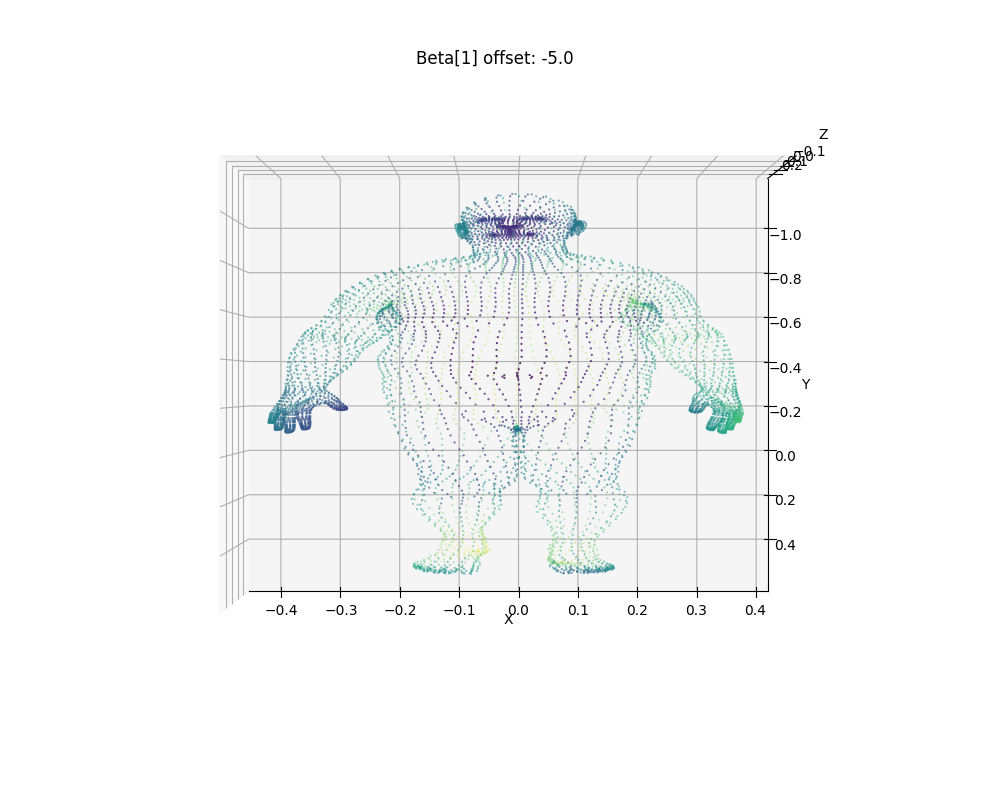

In [52]:
import os
import sys
os.environ['PYOPENGL_PLATFORM'] = 'egl'
os.environ['CUDA_VISIBLE_DEVICES'] = '1'

conda_prefix = sys.prefix
os.environ['PATH'] = f"{conda_prefix}/bin:" + os.environ['PATH']

import cv2
import torch
import numpy as np
from tqdm import tqdm
from multi_person_tracker import MPT
from torch.utils.data import DataLoader

from lib.models.vibe import VIBE_Demo
from lib.dataset.inference import Inference
from lib.utils.demo_utils import download_ckpt

# ============ ADD THESE TWO IMPORTS ============
from lib.models.smpl import SMPL  # ← The SMPL wrapper class you just found
from lib.core.config import VIBE_DATA_DIR  # ← Path to SMPL model files
# ==============================================

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

MIN_NUM_FRAMES = 15

def test_fatness(image_folder, fatness_offset):
    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
    
    # Get existing frames
    image_files = sorted([f for f in os.listdir(image_folder) if f.endswith('.png')])
    first_img_path = os.path.join(image_folder, image_files[0])
    sample_img = cv2.imread(first_img_path)
    orig_height, orig_width = sample_img.shape[:2]
    num_frames = len(image_files)
    
    print(f"Found {num_frames} frames at {image_folder}")
    print(f"Image size: {orig_width}x{orig_height}")
    
    # Run tracking (from demo.py)
    mot = MPT(
        device=device,
        batch_size=12,
        display=False,
        detector_type='yolo',
        output_format='dict',
        yolo_img_size=416,
    )
    tracking_results = mot(image_folder)
    
    person_id = list(tracking_results.keys())[0]
    bboxes = tracking_results[person_id]['bbox']
    frames = tracking_results[person_id]['frames']
    
    print(f"Processing {len(frames)} frames for person {person_id}")
    
    # Load VIBE model (from demo.py)
    model = VIBE_Demo(
        seqlen=15,
        n_layers=2,
        hidden_size=1024,
        add_linear=True,
        use_residual=True,
    ).to(device)
    
    pretrained_file = download_ckpt(use_3dpw=False)
    ckpt = torch.load(pretrained_file, map_location='cpu')
    model.load_state_dict(ckpt['gen_state_dict'], strict=False)
    model.eval()
    print(f'Loaded pretrained weights')
    
    # Prepare dataset (from demo.py)
    dataset = Inference(
        image_folder=image_folder,
        frames=frames,
        bboxes=bboxes,
        joints2d=None,
        scale=1.1,
    )
    
    dataloader = DataLoader(dataset, batch_size=450, num_workers=16)
    
    # Run VIBE inference (from demo.py lines 212-243)
    # WHY: VIBE predicts camera, pose, and shape parameters
    with torch.no_grad():
        pred_cam, pred_verts, pred_pose, pred_betas = [], [], [], []
        
        for batch in dataloader:
            batch = batch.unsqueeze(0).to(device)
            batch_size, seqlen = batch.shape[:2]
            output = model(batch)[-1]
            
            # WHY these lines: Extract the 85 predicted parameters
            # theta = [3 camera | 72 pose | 10 shape]
            pred_cam.append(output['theta'][:, :, :3].reshape(batch_size * seqlen, -1))
            pred_verts.append(output['verts'].reshape(batch_size * seqlen, -1, 3))
            pred_pose.append(output['theta'][:,:,3:75].reshape(batch_size * seqlen, -1))
            pred_betas.append(output['theta'][:, :,75:].reshape(batch_size * seqlen, -1))
        
        pred_cam = torch.cat(pred_cam, dim=0)
        pred_verts = torch.cat(pred_verts, dim=0)
        pred_pose = torch.cat(pred_pose, dim=0)
        pred_betas = torch.cat(pred_betas, dim=0)
    
    # Convert to numpy (from demo.py lines 315-321)
    # WHY: Easier to work with numpy arrays for modification
    pred_cam = pred_cam.cpu().numpy()
    pred_verts = pred_verts.cpu().numpy()
    pred_pose = pred_pose.cpu().numpy()
    pred_betas = pred_betas.cpu().numpy()
    
    # ============ MODIFY BETA[1] ============
    # WHY: beta[1] controls body weight/fatness
    print(f"\nOriginal beta[1]: {pred_betas[0, 1]:.4f}")
    pred_betas[:, 1] += fatness_offset
    print(f"Modified beta[1]: {pred_betas[0, 1]:.4f} (offset: {fatness_offset})")
    
    # ============ REGENERATE VERTICES ============
    # WHY: pred_verts from VIBE are based on OLD beta values
    # We need to regenerate vertices using SMPL with the NEW beta values
    print("Regenerating vertices with modified beta...")
    
    # WHY this line: Create SMPL model to convert parameters → vertices
    smpl = SMPL(
        VIBE_DATA_DIR,  # Path to SMPL model files
        batch_size=1,
        create_transl=False
    ).to(device)
    
    new_verts = []
    # WHY this loop: Regenerate mesh for each frame with new beta
    for i in tqdm(range(len(pred_betas)), desc="Regenerating"):
        with torch.no_grad():
            # WHY: Convert numpy → torch tensors for SMPL
            beta_torch = torch.tensor(pred_betas[i:i+1], dtype=torch.float32).to(device)
            pose_torch = torch.tensor(pred_pose[i:i+1], dtype=torch.float32).to(device)
            
            # WHY: SMPL takes pose in specific format (body_pose + global_orient)
            # pose_torch[:, :3] = global rotation (root joint)
            # pose_torch[:, 3:] = body pose (23 joints)
            output = smpl(
                betas=beta_torch,
                body_pose=pose_torch[:, 3:],
                global_orient=pose_torch[:, :3]
            )
            # WHY: Extract the new vertices and convert back to numpy
            new_verts.append(output.vertices[0].cpu().numpy())
    
    pred_verts = np.array(new_verts)
    print("✓ Vertices regenerated!")
    
    # ============ PLOT 3D ============
    frame_idx = 0
    vertices = pred_verts[frame_idx]
    
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    x = vertices[:, 0]
    y = vertices[:, 1]
    z = vertices[:, 2]
    
    ax.scatter(x, y, z, c=z, cmap='viridis', marker='.', s=1)
    ax.view_init(elev=-90, azim=-90)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(f'Beta[1] offset: {fatness_offset}')
    
    plt.tight_layout()
    plt.show()
    
    # Cleanup
    del model, smpl
    torch.cuda.empty_cache()
    
    return vertices

# Run test
if __name__ == '__main__':
    image_folder = '/x4/ljiao/Bhanu/VIBE/output/output_6_mkv_frames'
    test_fatness(image_folder, fatness_offset=-5.0)